## 1 - Goal/hypothesis

**Is implied volatility higher for options expiring near a company's earnings date than for options expiring later, well past it? And how does implied volatility vary as earnings announcements approach?**

**Hypothesis:**
Options that expire close to a company's earnings date have a significantly higher implied volatility than options on the same stock that expire much later.
As earnings announcements approach, implied volatility for near-term options will increase and then drop after the announcement.

## 2 - Collecting earnings data

In [1]:
TICKERS = [
    "AAPL", "MSFT", "NVDA", "GOOGL", "AMZN", "META", "TSLA",       # tech/mega-cap
    "JPM", "BAC", "GS", "V", "MA",                                  # financials
    "UNH", "JNJ", "PFE", "MRK", "ABBV",                             # healthcare
    "XOM", "CVX",                                                    # energy
    "PG", "KO", "PEP", "WMT", "COST", "HD",                         # consumer staples/retail
    "DIS", "NFLX",                                                   # media
    "ADBE", "CRM", "AMD", "INTC",                                   # tech (software/semis)
]



In [2]:
#Earnings data

import pandas as pd
import yfinance as yf

def get_earnings_dates(ticker: str, limit: int = 20) -> pd.DataFrame:
    """Pull past + upcoming earnings dates/EPS data for a single ticker via yfinance."""
    df = yf.Ticker(ticker).get_earnings_dates(limit=limit)
    df = df.rename_axis("Earnings Date").reset_index()
    df.insert(0, "Ticker", ticker)
    return df

earnings_data = {}
for t in TICKERS:
    try:
        earnings_data[t] = get_earnings_dates(t)
    except Exception as e:
        print(f"Failed to get earnings dates for {t}: {e}")

# Combine into one long DataFrame for convenience
earnings_df = pd.concat(earnings_data.values(), ignore_index=True)
earnings_df["Earnings Date"] = pd.to_datetime(earnings_df["Earnings Date"]).dt.tz_localize(None)
earnings_df.head(10)

,Ticker,Earnings Date,EPS Estimate,Reported EPS,Surprise(%)
0,AAPL,2026-10-29 16:00:00,1.98,NaN,NaN
1,AAPL,2026-07-30 16:00:00,1.89,2.02,6.74
2,AAPL,2026-04-30 16:00:00,1.94,2.01,3.46
3,AAPL,2026-01-29 16:00:00,2.67,2.84,6.25
4,AAPL,2025-10-30 16:00:00,1.77,1.85,4.52
5,AAPL,2025-07-31 16:00:00,1.43,1.57,9.48
6,AAPL,2025-05-01 16:00:00,1.62,1.65,1.69
7,AAPL,2025-01-30 16:00:00,2.35,2.40,2.26
8,AAPL,2024-10-31 16:00:00,0.95,0.97,2.48
9,AAPL,2024-08-01 16:00:00,1.34,1.40,4.36


In [3]:
#Keep only future earnings dates

now = pd.Timestamp.now(tz="UTC")

earnings_dates_utc = pd.to_datetime(earnings_df["Earnings Date"], utc=True)
upcoming_earnings = earnings_df[earnings_dates_utc >= now].sort_values("Earnings Date")
upcoming_earnings["Earnings Date"] = pd.to_datetime(upcoming_earnings["Earnings Date"]).dt.tz_localize(None)
upcoming_earnings

,Ticker,Earnings Date,EPS Estimate,Reported EPS,Surprise(%)
525,PEP,2026-10-08 08:00:00,2.30,NaN,NaN
175,JPM,2026-10-13 08:00:00,5.91,NaN,NaN
225,GS,2026-10-13 08:00:00,15.73,NaN,NaN
300,UNH,2026-10-13 08:00:00,4.15,NaN,NaN
325,JNJ,2026-10-13 08:00:00,2.45,NaN,NaN
200,BAC,2026-10-14 08:00:00,1.17,NaN,NaN
500,KO,2026-10-20 08:00:00,0.88,NaN,NaN
650,NFLX,2026-10-20 16:00:00,0.82,NaN,NaN
150,TSLA,2026-10-21 16:00:00,0.46,NaN,NaN
475,PG,2026-10-22 08:00:00,1.89,NaN,NaN


## 3 - Collecting option chain data

In [4]:
#Option chain data for tickers with upcoming earnings

from datetime import datetime, timezone

def get_option_chain(ticker: str) -> pd.DataFrame:
    """Pull the full current option chain (all expirations, calls + puts) for one ticker."""
    tk = yf.Ticker(ticker)
    snapshot_time = datetime.now(timezone.utc)
    underlying_price = tk.fast_info.get("lastPrice")

    frames = []
    for expiry in tk.options:  # all available expiration dates, as strings "YYYY-MM-DD"
        chain = tk.option_chain(expiry)
        for option_type, df in (("call", chain.calls), ("put", chain.puts)):
            df = df.copy()
            df.insert(0, "Ticker", ticker)
            df.insert(1, "Type", option_type)
            df.insert(2, "Expiration", pd.Timestamp(expiry))
            frames.append(df)

    result = pd.concat(frames, ignore_index=True)
    result["SnapshotTime"] = snapshot_time
    result["UnderlyingPrice"] = underlying_price
    result["DaysToExpiry"] = (result["Expiration"] - pd.Timestamp(snapshot_time.date())).dt.days

    # Keep/rename the columns
    result = result.rename(columns={
        "strike": "Strike",
        "lastPrice": "LastPrice",
        "bid": "Bid",
        "ask": "Ask",
        "volume": "Volume",
        "openInterest": "OpenInterest",
        "impliedVolatility": "ImpliedVolatility",
        "inTheMoney": "InTheMoney",
    })
    cols = ["Ticker", "Type", "Expiration", "DaysToExpiry", "Strike", "LastPrice", "Bid", "Ask",
            "Volume", "OpenInterest", "ImpliedVolatility", "InTheMoney", "UnderlyingPrice", "SnapshotTime"]
    return result[cols]

options_data = {}
for t in upcoming_earnings["Ticker"]:
    try:
        options_data[t] = get_option_chain(t)
    except Exception as e:
        print(f"Failed to get option chain for {t}: {e}")

# Combine into one long DataFrame for convenience
options_df = pd.concat(options_data.values(), ignore_index=True)
options_df.head(10)

,Ticker,Type,Expiration,DaysToExpiry,Strike,LastPrice,Bid,Ask,Volume,OpenInterest,ImpliedVolatility,InTheMoney,UnderlyingPrice,SnapshotTime
0,PEP,call,2026-09-25,0,75.0,55.50,51.60,53.95,NaN,24.0,7.000001,True,127.800003,2026-09-25 14:04:05.178265+00:00
1,PEP,call,2026-09-25,0,80.0,48.44,46.60,49.30,3.0,10.0,4.281255,True,127.800003,2026-09-25 14:04:05.178265+00:00
2,PEP,call,2026-09-25,0,85.0,43.52,41.20,44.10,5.0,13.0,5.796878,True,127.800003,2026-09-25 14:04:05.178265+00:00
3,PEP,call,2026-09-25,0,118.0,13.03,8.60,10.35,NaN,2.0,1.341800,True,127.800003,2026-09-25 14:04:05.178265+00:00
4,PEP,call,2026-09-25,0,119.0,12.10,7.60,9.55,NaN,2.0,1.374027,True,127.800003,2026-09-25 14:04:05.178265+00:00
5,PEP,call,2026-09-25,0,123.0,4.70,4.25,5.20,380.0,115.0,0.731448,True,127.800003,2026-09-25 14:04:05.178265+00:00
6,PEP,call,2026-09-25,0,124.0,4.90,3.25,4.15,2.0,33.0,0.597660,True,127.800003,2026-09-25 14:04:05.178265+00:00
7,PEP,call,2026-09-25,0,125.0,3.45,1.70,3.45,4.0,82.0,0.642093,True,127.800003,2026-09-25 14:04:05.178265+00:00
8,PEP,call,2026-09-25,0,126.0,2.60,0.69,2.12,5.0,14.0,0.364264,True,127.800003,2026-09-25 14:04:05.178265+00:00
9,PEP,call,2026-09-25,0,127.0,0.71,0.57,1.22,26.0,7.0,0.283210,True,127.800003,2026-09-25 14:04:05.178265+00:00


## 4 - Classifying options as near-term or far-term, relative to earnings date

In [5]:
#merge earnings date from upcoming_earnings with options_df on Ticker to get a combined DataFrame with both earnings and options data
options_df = options_df.merge(
    upcoming_earnings[["Ticker", "Earnings Date"]],
    on="Ticker",
    how="inner"
)
options_df.head(10)

,Ticker,Type,Expiration,DaysToExpiry,Strike,LastPrice,Bid,Ask,Volume,OpenInterest,ImpliedVolatility,InTheMoney,UnderlyingPrice,SnapshotTime,Earnings Date
0,PEP,call,2026-09-25,0,75.0,55.50,51.60,53.95,NaN,24.0,7.000001,True,127.800003,2026-09-25 14:04:05.178265+00:00,2026-10-08 08:00:00
1,PEP,call,2026-09-25,0,80.0,48.44,46.60,49.30,3.0,10.0,4.281255,True,127.800003,2026-09-25 14:04:05.178265+00:00,2026-10-08 08:00:00
2,PEP,call,2026-09-25,0,85.0,43.52,41.20,44.10,5.0,13.0,5.796878,True,127.800003,2026-09-25 14:04:05.178265+00:00,2026-10-08 08:00:00
3,PEP,call,2026-09-25,0,118.0,13.03,8.60,10.35,NaN,2.0,1.341800,True,127.800003,2026-09-25 14:04:05.178265+00:00,2026-10-08 08:00:00
4,PEP,call,2026-09-25,0,119.0,12.10,7.60,9.55,NaN,2.0,1.374027,True,127.800003,2026-09-25 14:04:05.178265+00:00,2026-10-08 08:00:00
5,PEP,call,2026-09-25,0,123.0,4.70,4.25,5.20,380.0,115.0,0.731448,True,127.800003,2026-09-25 14:04:05.178265+00:00,2026-10-08 08:00:00
6,PEP,call,2026-09-25,0,124.0,4.90,3.25,4.15,2.0,33.0,0.597660,True,127.800003,2026-09-25 14:04:05.178265+00:00,2026-10-08 08:00:00
7,PEP,call,2026-09-25,0,125.0,3.45,1.70,3.45,4.0,82.0,0.642093,True,127.800003,2026-09-25 14:04:05.178265+00:00,2026-10-08 08:00:00
8,PEP,call,2026-09-25,0,126.0,2.60,0.69,2.12,5.0,14.0,0.364264,True,127.800003,2026-09-25 14:04:05.178265+00:00,2026-10-08 08:00:00
9,PEP,call,2026-09-25,0,127.0,0.71,0.57,1.22,26.0,7.0,0.283210,True,127.800003,2026-09-25 14:04:05.178265+00:00,2026-10-08 08:00:00


In [6]:
#drop dead quotes and placeholders/failed IV calculations
options_df = options_df[(options_df["Bid"] > 0) & (options_df["Ask"] > 0)& (options_df["ImpliedVolatility"] > 0.01)]

#filter to OTM options 
options_df = options_df[
    ((options_df["Type"] == "call") & (options_df["Strike"] >= options_df["UnderlyingPrice"])) |
    ((options_df["Type"] == "put") & (options_df["Strike"] <= options_df["UnderlyingPrice"]))
]

#filter to options that expire after earnings date
options_df = options_df[options_df['Expiration'] >= options_df['Earnings Date']]

#for each ticker, rank the remaining expiration dates and keep only the closest two:
#rank 1 (soonest after earnings) = near_term, rank 2 (next one out) = far_term
expiry_rank = (
    options_df[["Ticker", "Expiration"]]
    .drop_duplicates()
    .sort_values(["Ticker", "Expiration"])
)
expiry_rank["ExpiryRank"] = expiry_rank.groupby("Ticker").cumcount() + 1

options_df = options_df.merge(expiry_rank, on=["Ticker", "Expiration"], how="left")
options_df = options_df[options_df["ExpiryRank"] <= 2].copy()
options_df["Term"] = options_df["ExpiryRank"].map({1: "near_term", 2: "far_term"})
options_df = options_df.drop(columns="ExpiryRank")
options_df

,Ticker,Type,Expiration,DaysToExpiry,Strike,LastPrice,Bid,Ask,Volume,OpenInterest,ImpliedVolatility,InTheMoney,UnderlyingPrice,SnapshotTime,Earnings Date,Term
0,PEP,call,2026-10-09,14,128.0,2.95,2.72,3.30,1.0,26.0,0.328620,False,127.800003,2026-09-25 14:04:05.178265+00:00,2026-10-08 08:00:00,near_term
1,PEP,call,2026-10-09,14,129.0,2.33,2.17,2.72,11.0,79.0,0.316413,False,127.800003,2026-09-25 14:04:05.178265+00:00,2026-10-08 08:00:00,near_term
2,PEP,call,2026-10-09,14,130.0,1.90,1.90,2.13,8.0,124.0,0.298103,False,127.800003,2026-09-25 14:04:05.178265+00:00,2026-10-08 08:00:00,near_term
3,PEP,call,2026-10-09,14,131.0,1.65,1.60,1.82,3.0,60.0,0.302497,False,127.800003,2026-09-25 14:04:05.178265+00:00,2026-10-08 08:00:00,near_term
4,PEP,call,2026-10-09,14,132.0,1.70,1.30,1.77,162.0,334.0,0.330817,False,127.800003,2026-09-25 14:04:05.178265+00:00,2026-10-08 08:00:00,near_term
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20844,COST,put,2027-01-15,112,870.0,27.09,19.55,24.15,1.0,469.0,0.221672,False,917.669983,2026-09-25 14:05:04.137735+00:00,2026-12-10 15:00:00,far_term
20845,COST,put,2027-01-15,112,880.0,32.91,23.10,27.15,62.0,671.0,0.217797,False,917.669983,2026-09-25 14:05:04.137735+00:00,2026-12-10 15:00:00,far_term
20846,COST,put,2027-01-15,112,890.0,29.37,26.65,31.40,23.0,1537.0,0.218788,False,917.669983,2026-09-25 14:05:04.137735+00:00,2026-12-10 15:00:00,far_term
20847,COST,put,2027-01-15,112,900.0,31.03,30.00,34.60,28.0,1465.0,0.212631,False,917.669983,2026-09-25 14:05:04.137735+00:00,2026-12-10 15:00:00,far_term


## 5 - Find the ATM option and compute average IV per ticker/term

For each ticker and term category, find the strike closest to the current stock price (most reliable IV), then average call and put IV at that strike.

In [7]:
options_df['StrikeDistance'] = abs(options_df['Strike'] - options_df['UnderlyingPrice'])

options_df.head()

,Ticker,Type,Expiration,DaysToExpiry,Strike,LastPrice,Bid,Ask,Volume,OpenInterest,ImpliedVolatility,InTheMoney,UnderlyingPrice,SnapshotTime,Earnings Date,Term,StrikeDistance
0,PEP,call,2026-10-09,14,128.0,2.95,2.72,3.30,1.0,26.0,0.328620,False,127.800003,2026-09-25 14:04:05.178265+00:00,2026-10-08 08:00:00,near_term,0.199997
1,PEP,call,2026-10-09,14,129.0,2.33,2.17,2.72,11.0,79.0,0.316413,False,127.800003,2026-09-25 14:04:05.178265+00:00,2026-10-08 08:00:00,near_term,1.199997
2,PEP,call,2026-10-09,14,130.0,1.90,1.90,2.13,8.0,124.0,0.298103,False,127.800003,2026-09-25 14:04:05.178265+00:00,2026-10-08 08:00:00,near_term,2.199997
3,PEP,call,2026-10-09,14,131.0,1.65,1.60,1.82,3.0,60.0,0.302497,False,127.800003,2026-09-25 14:04:05.178265+00:00,2026-10-08 08:00:00,near_term,3.199997
4,PEP,call,2026-10-09,14,132.0,1.70,1.30,1.77,162.0,334.0,0.330817,False,127.800003,2026-09-25 14:04:05.178265+00:00,2026-10-08 08:00:00,near_term,4.199997


In [8]:
#For each (Ticker, Expiration, Type) group, the ATM option is the row with the minimum StrikeDistance

atm_idx = options_df.groupby(["Ticker", "Expiration", "Type"])["StrikeDistance"].idxmin()
atm_options = options_df.loc[atm_idx].reset_index(drop=True)
atm_options["DaysToExpiry"] = atm_options["DaysToExpiry"] / 365
atm_options = atm_options.rename(columns={"DaysToExpiry": "YearsToExpiry"})
atm_options

,Ticker,Type,Expiration,YearsToExpiry,Strike,LastPrice,Bid,Ask,Volume,OpenInterest,ImpliedVolatility,InTheMoney,UnderlyingPrice,SnapshotTime,Earnings Date,Term,StrikeDistance
0,AAPL,call,2026-10-30,0.095890,340.0,9.10,9.15,9.55,20.0,1005.0,0.275825,False,335.505005,2026-09-25 14:04:44.438137+00:00,2026-10-29 16:00:00,near_term,4.494995
1,AAPL,put,2026-10-30,0.095890,335.0,9.85,9.40,9.95,15.0,278.0,0.242714,False,335.505005,2026-09-25 14:04:44.438137+00:00,2026-10-29 16:00:00,near_term,0.505005
2,AAPL,call,2026-11-20,0.153425,340.0,12.28,12.20,12.40,73.0,9558.0,0.273292,False,335.505005,2026-09-25 14:04:44.438137+00:00,2026-10-29 16:00:00,far_term,4.494995
3,AAPL,put,2026-11-20,0.153425,335.0,12.15,11.85,12.35,223.0,2743.0,0.238380,False,335.505005,2026-09-25 14:04:44.438137+00:00,2026-10-29 16:00:00,far_term,0.505005
4,ABBV,call,2026-10-30,0.095890,265.0,9.58,7.30,9.85,4.0,19.0,0.330207,False,262.801788,2026-09-25 14:04:37.703440+00:00,2026-10-29 08:00:00,near_term,2.198212
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119,WMT,put,2026-12-18,0.230137,105.0,4.10,3.95,4.25,4.0,5904.0,0.262459,False,107.389999,2026-09-25 14:04:59.316974+00:00,2026-11-19 07:00:00,far_term,2.389999
120,XOM,call,2026-11-20,0.153425,165.0,5.50,5.45,5.75,19.0,3622.0,0.296272,False,160.975006,2026-09-25 14:04:46.700287+00:00,2026-10-30 08:00:00,near_term,4.024994
121,XOM,put,2026-11-20,0.153425,160.0,7.10,6.90,7.55,756.0,3830.0,0.316901,False,160.975006,2026-09-25 14:04:46.700287+00:00,2026-10-30 08:00:00,near_term,0.975006
122,XOM,call,2026-12-18,0.230137,165.0,7.35,7.10,7.65,1.0,6711.0,0.304389,False,160.975006,2026-09-25 14:04:46.700287+00:00,2026-10-30 08:00:00,far_term,4.024994


In [9]:
#Average ATM implied volatility across call/put, per ticker and term, with years to expiry
atm_iv_by_ticker_term = (
    atm_options.groupby(["Ticker", "Term"])
    .agg(AvgATM_IV=("ImpliedVolatility", "mean"), YearsToExpiry=("YearsToExpiry", "first"))
    .reset_index()
)
atm_iv_by_ticker_term

#So now each ticker has a far_term option, and a near_term option, with average atm implied volatility and yearstoexpiry for each term

,Ticker,Term,AvgATM_IV,YearsToExpiry
0,AAPL,far_term,0.255836,0.153425
1,AAPL,near_term,0.259269,0.095890
2,ABBV,far_term,0.322913,0.153425
3,ABBV,near_term,0.322272,0.095890
4,ADBE,far_term,0.443685,0.306849
...,...,...,...,...
57,V,near_term,0.251655,0.095890
58,WMT,far_term,0.276252,0.230137
59,WMT,near_term,0.290718,0.153425
60,XOM,far_term,0.307136,0.230137


## 6 - Building final ticker-level dataframe with average ATM IV for near-term and far-term options

In [10]:
#Pivot IV: Pivot to one row per ticker, with near_term and far_term IV in separate columns
event_var_df = atm_iv_by_ticker_term.pivot(index="Ticker", columns="Term", values="AvgATM_IV").reset_index()
event_var_df.columns.name = None
#add spread col
event_var_df["IV_Spread"] = event_var_df["near_term"] - event_var_df["far_term"]
event_var_df

days_by_ticker_term = atm_options.groupby(["Ticker", "Term"])["YearsToExpiry"].mean().reset_index()
days_pivot = days_by_ticker_term.pivot(index="Ticker", columns="Term", values="YearsToExpiry").reset_index()
days_pivot.columns.name = None
days_pivot = days_pivot.rename(columns={"near_term": "near_years", "far_term": "far_years"})
days_pivot["T_near"] = days_pivot["near_years"]

# Merge and compute EventVariance = T_near * (near_term^2 - far_term^2) --> amount of extra volatility due to earnings event, scaled by time to expiry of near-term option
event_var_df = event_var_df.merge(days_pivot[["Ticker", "T_near"]], on="Ticker")
event_var_df["EventVariance"] = event_var_df["T_near"] * (event_var_df["near_term"]**2 - event_var_df["far_term"]**2)
event_var_df  

,Ticker,far_term,near_term,IV_Spread,T_near,EventVariance
0,AAPL,0.255836,0.259269,0.003433,0.095890,0.000170
1,ABBV,0.322913,0.322272,-0.000641,0.095890,-0.000040
2,ADBE,0.443685,0.453359,0.009674,0.230137,0.001997
3,AMD,0.563969,0.574231,0.010261,0.153425,0.001792
4,AMZN,0.370566,0.391028,0.020462,0.095890,0.001494
5,BAC,0.334113,0.295539,-0.038574,0.057534,-0.001397
6,COST,0.230770,0.235588,0.004818,0.230137,0.000517
7,CRM,0.453527,0.464880,0.011352,0.230137,0.002399
8,CVX,0.276191,0.292335,0.016144,0.153425,0.001408
9,DIS,0.323585,0.347174,0.023590,0.153425,0.002428


## 7 - Statistical test to compare near-term and far-term IV

In [11]:
#t-test to see if the mean spread is significantly greater than 0 (i.e., near-term IV is significantly higher than far-term IV)

from scipy import stats

t_stat, p_value = stats.ttest_1samp(event_var_df["IV_Spread"], popmean=0, alternative="greater")

print(f"n = {len(event_var_df)}")
print(f"mean iv spread = {event_var_df['IV_Spread'].mean():.4f}")
print(f"t-statistic = {t_stat:.4f}")
print(f"p-value (one-sided, H1: mean > 0) = {p_value:.4f}")


n = 31
mean iv spread = 0.0099
t-statistic = 3.6806
p-value (one-sided, H1: mean > 0) = 0.0005


In [12]:
#t-test to see if the event variance is significantly greater than 0 (i.e., near-term IV is significantly higher than far-term IV)

from scipy import stats

t_stat, p_value = stats.ttest_1samp(event_var_df["EventVariance"], popmean=0, alternative="greater")

print(f"n = {len(event_var_df)}")
print(f"mean event variance = {event_var_df['EventVariance'].mean():.4f}")
print(f"t-statistic = {t_stat:.4f}")
print(f"p-value (one-sided, H1: mean > 0) = {p_value:.4f}")


n = 31
mean event variance = 0.0008
t-statistic = 4.4093
p-value (one-sided, H1: mean > 0) = 0.0001


## 8 - Visualization

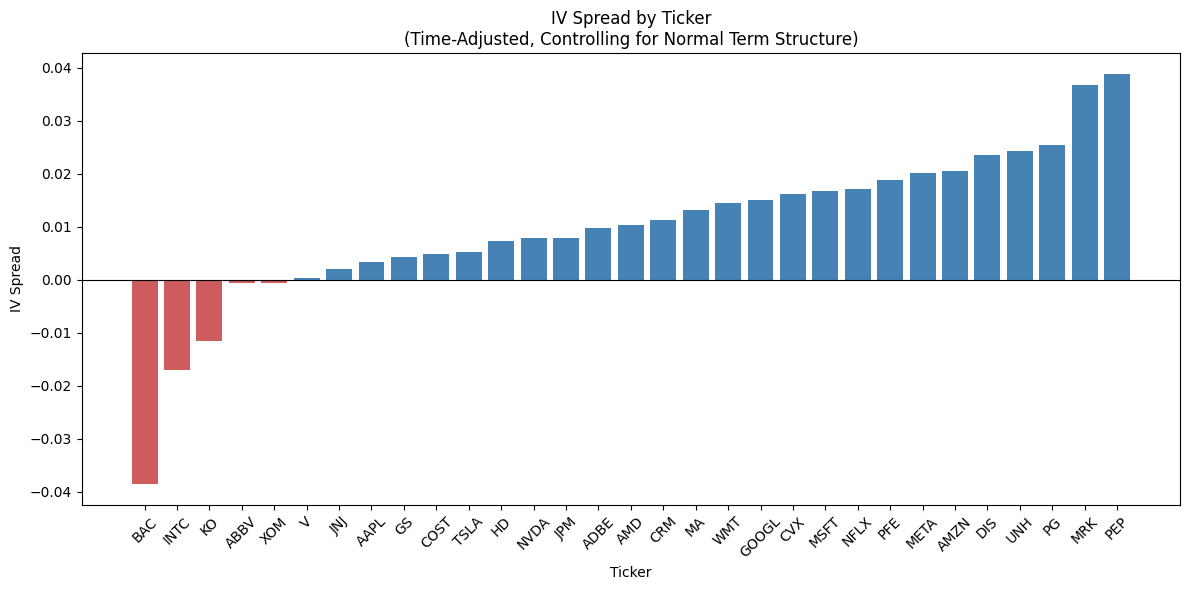

In [13]:
#visualization of IV spread by ticker

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
colors = ["steelblue" if x > 0 else "indianred" for x in event_var_df.sort_values("IV_Spread")["IV_Spread"]]
plt.bar(event_var_df.sort_values("IV_Spread")["Ticker"], event_var_df.sort_values("IV_Spread")["IV_Spread"], color=colors)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("IV Spread by Ticker\n(Time-Adjusted, Controlling for Normal Term Structure)")
plt.xlabel("Ticker")
plt.ylabel("IV Spread")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

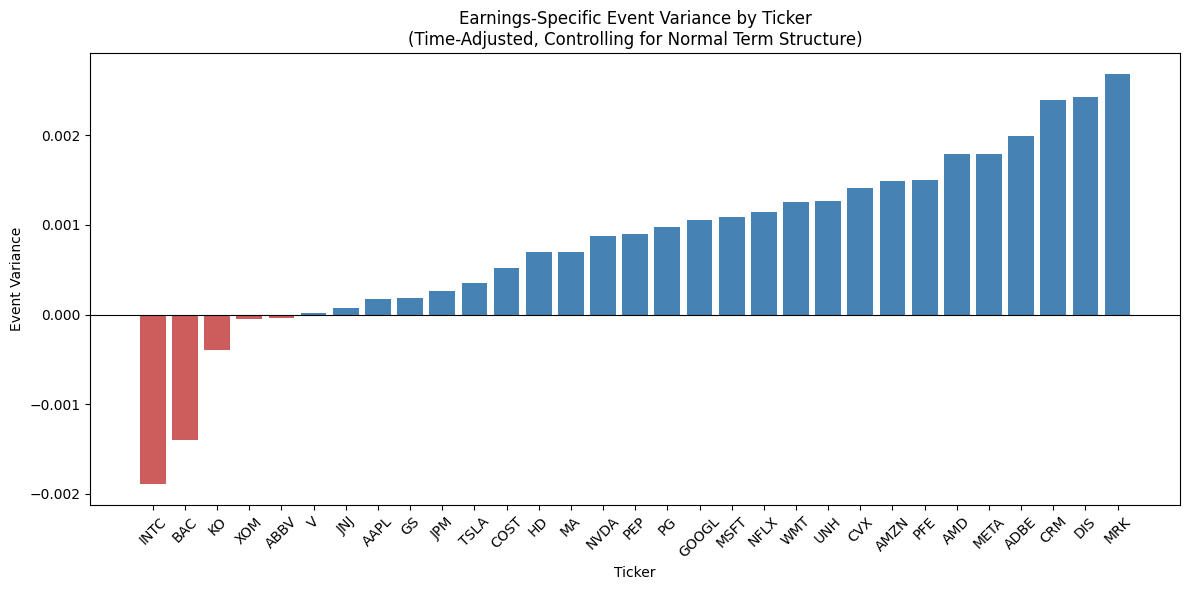

In [14]:
#visualization of event variance by ticker

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
colors = ["steelblue" if x > 0 else "indianred" for x in event_var_df.sort_values("EventVariance")["EventVariance"]]
plt.bar(event_var_df.sort_values("EventVariance")["Ticker"], event_var_df.sort_values("EventVariance")["EventVariance"], color=colors)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Earnings-Specific Event Variance by Ticker\n(Time-Adjusted, Controlling for Normal Term Structure)")
plt.xlabel("Ticker")
plt.ylabel("Event Variance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Implied volatility is generally higher for options that expire near a company's earnings date (short-term options) compared to options that expire well after the earnings date (long-term options). At first, I analyzed the implied volatility spread between near-term and far-term options for each ticker (IV spread = near-term IV - far-term IV), however, this did not account for the fact that near-term and far-term IV differ even when there are no earnings in sight. To account for this, I used the event variance to isolate the effect of earnings on implied volatility. The event variance is calculated as the difference between the near-term and far-term IV, minus the average difference between near-term and far-term IV for that ticker. This allows us to see how much of the IV is due to the earnings event itself, rather than other factors.

After analyzing event variance for each ticker, we see by both the visualization and the one-sided t-test that the event variance is significantly greater than zero, indicating that near-term options have a higher implied volatility than far-term options.

This supports the idea that a near-term option expiring shortly after an earnings announcement has most of its remaining lifespan concentrated around that earnings event, leading to the most uncertainty and thus higher implied volatility. In contrast, a far-term option has a longer time to expiration, which allows for more time for the stock price to stabilize after the earnings announcement, resulting in lower implied volatility.

## 9 - Investigating negative outliers

In [15]:
for ticker in ["INTC", "JNJ", "KO", "TSLA", "UNH"]:
    future = earnings_df[
        (earnings_df["Ticker"] == ticker) &
        (earnings_df["Earnings Date"] > pd.Timestamp.now())
    ].sort_values("Earnings Date")
    print(f"\n{ticker}:")
    print(future[["Earnings Date"]])


INTC:
          Earnings Date
750 2026-10-22 16:00:00

JNJ:
          Earnings Date
325 2026-10-13 08:00:00

KO:
          Earnings Date
500 2026-10-20 08:00:00

TSLA:
          Earnings Date
150 2026-10-21 16:00:00

UNH:
          Earnings Date
300 2026-10-13 08:00:00


In [16]:
event_var_df = event_var_df.merge(days_pivot[["Ticker", "near_years", "far_years"]], on="Ticker")
event_var_df["ExpiryGapDays"] = (event_var_df["far_years"] - event_var_df["near_years"]) * 365
event_var_df[event_var_df["Ticker"].isin(["INTC", "JNJ", "KO", "TSLA", "UNH"])][
    ["Ticker", "near_term", "far_term", "EventVariance", "ExpiryGapDays"]
]

,Ticker,near_term,far_term,EventVariance,ExpiryGapDays
13,INTC,0.713626,0.730716,-0.001894,7.0
14,JNJ,0.296180,0.294105,0.000070,7.0
16,KO,0.220101,0.231575,-0.000398,7.0
26,TSLA,0.450323,0.445135,0.000356,7.0
27,UNH,0.466833,0.442571,0.001269,7.0


These negative outliers exist because they all have a very narrow expiry gap between near-term and far-term options. This means that the spread is small enough that noise can push the event variance in the negative.

## 10 - Daily IV tracking (started 9/18)

In [17]:
#Lock in tickers + earnings dates once, then track the same option series every day
#so the ramp into earnings and crush after it are comparable day to day
import os

CONFIG_PATH = "snapshot_config.csv"
LOG_PATH = "iv_tracking_log.csv"

if os.path.exists(CONFIG_PATH):
    #reuse the tickers/expirations locked in on the first run
    snapshot_config = pd.read_csv(CONFIG_PATH, parse_dates=["EarningsDate", "TrackedExpiration"])
else:
    #first run: pick tickers with the earliest upcoming earnings
    candidates = upcoming_earnings.sort_values("Earnings Date")["Ticker"].head(6).tolist()

    locked_rows = []
    for t in candidates:
        earnings_date = upcoming_earnings.loc[upcoming_earnings["Ticker"] == t, "Earnings Date"].iloc[0]
        try:
            chain = get_option_chain(t)
            #first expiration cycle after earnings, so later snapshots can show the post-earnings IV crush
            post_earnings_expirations = chain.loc[chain["Expiration"] > earnings_date, "Expiration"]
            if post_earnings_expirations.empty:
                print(f"No expiration after earnings date found for {t}, skipping")
                continue
            locked_rows.append({
                "Ticker": t,
                "EarningsDate": earnings_date,
                "TrackedExpiration": post_earnings_expirations.min(),
            })
        except Exception as e:
            print(f"Could not lock expiration for {t}: {e}")

    snapshot_config = pd.DataFrame(locked_rows)
    snapshot_config.to_csv(CONFIG_PATH, index=False)

SNAPSHOT_TICKERS = snapshot_config["Ticker"].tolist()

def snapshot_near_term_iv(config_df):
    rows = []
    for _, cfg in config_df.iterrows():
        t = cfg["Ticker"]
        tracked_expiration = pd.Timestamp(cfg["TrackedExpiration"])
        earnings_date = pd.Timestamp(cfg["EarningsDate"])
        try:
            #pull option chain and keep only the locked expiration
            chain = get_option_chain(t)
            chain = chain[chain["Expiration"] == tracked_expiration]
            chain = chain[((chain["Type"] == "call") & (chain["Strike"] >= chain["UnderlyingPrice"])) |
            ((chain["Type"] == "put") & (chain["Strike"] <= chain["UnderlyingPrice"]))]

            if chain.empty:
                print(f"No quotes for {t} at tracked expiration {tracked_expiration.date()} (may have expired)")
                continue

            #atm strike
            atm_row = chain.loc[(chain["Strike"] - chain["UnderlyingPrice"]).abs().idxmin()]

            #record result
            rows.append({
                "Date": pd.Timestamp.now().normalize(),
                "Ticker": t,
                "EarningsDate": earnings_date,
                "Expiration": tracked_expiration,
                "ATM_IV": atm_row["ImpliedVolatility"],
            })
        except Exception as e:
            print(f"Error occurred while processing {t}: {e}")

    return pd.DataFrame(rows)

#run and save to file
today_snapshot = snapshot_near_term_iv(snapshot_config)
if os.path.exists(LOG_PATH):
    today_snapshot.to_csv(LOG_PATH, mode='a', header=False, index=False)
else:
    today_snapshot.to_csv(LOG_PATH, index=False)

today_snapshot

#each day, notebook is run to pull data for the same tickers at 10 am eastern. new data is appended to old in csv file

,Date,Ticker,EarningsDate,Expiration,ATM_IV
0,2026-09-25,COST,2026-09-24 16:00:00,2026-09-25,0.368903
1,2026-09-25,PEP,2026-10-08 08:00:00,2026-10-09,0.332526
2,2026-09-25,JPM,2026-10-13 08:00:00,2026-10-16,0.294380
3,2026-09-25,GS,2026-10-13 08:00:00,2026-10-16,0.316123
4,2026-09-25,UNH,2026-10-13 08:00:00,2026-10-16,0.511876
5,2026-09-25,JNJ,2026-10-13 08:00:00,2026-10-16,0.318977


## 11 - Daily IV Tracking Analysis

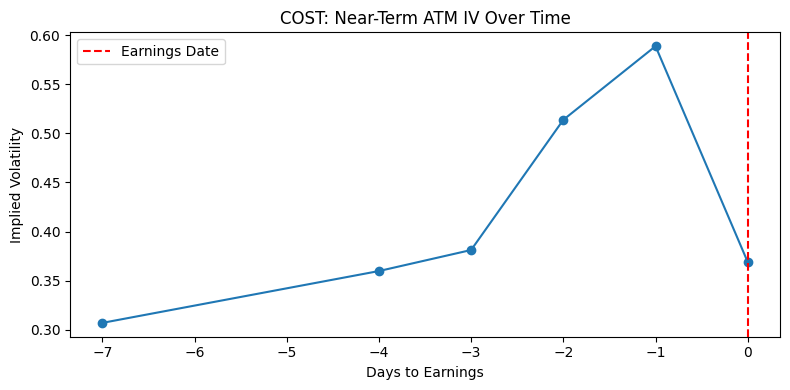

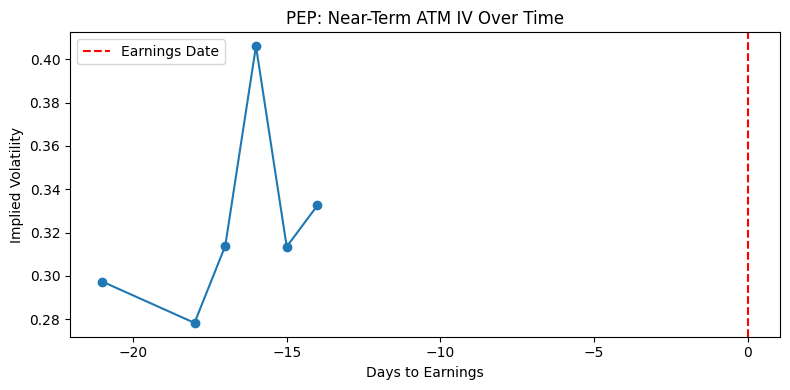

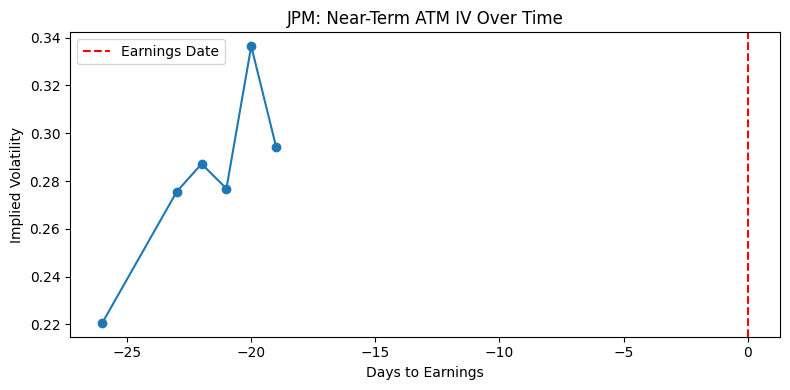

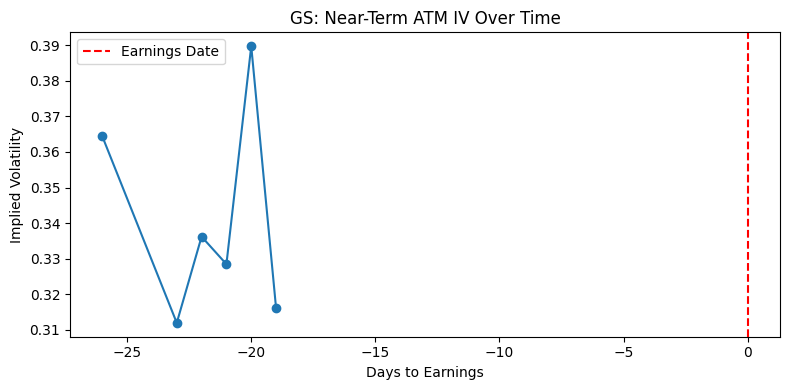

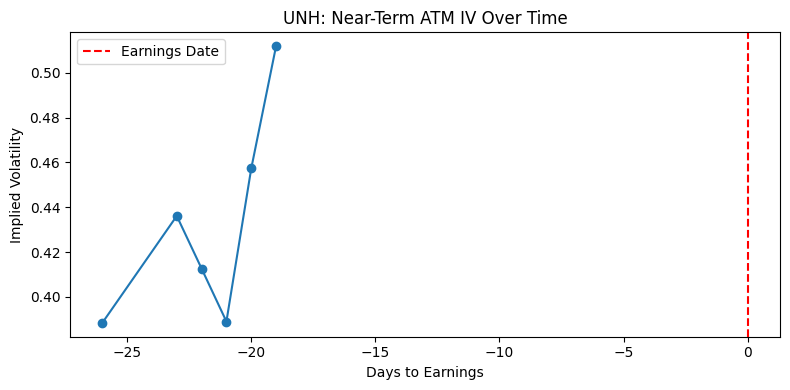

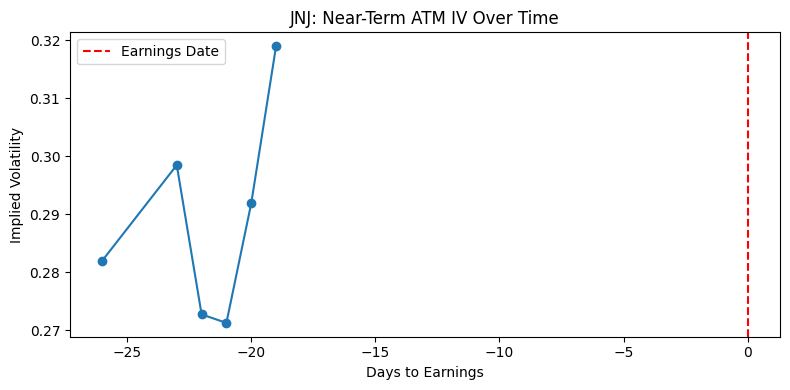

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
log = pd.read_csv("iv_tracking_log.csv", parse_dates=["Date", "EarningsDate"])

#gets data for each ticker
for ticker in log["Ticker"].unique():
    ticker_data = log[log["Ticker"] == ticker].sort_values("Date")
    earnings_date = ticker_data["EarningsDate"].iloc[0]

    #x-axis as days relative to earnings (0 = earnings date, negative = before, positive = after)
    days_to_earnings = (ticker_data["Date"] - earnings_date).dt.days

    plt.figure(figsize=(8, 4))
    plt.plot(days_to_earnings, ticker_data["ATM_IV"], marker="o")
    plt.axvline(0, color="red", linestyle="--", label="Earnings Date")
    plt.title(f"{ticker}: Near-Term ATM IV Over Time")
    plt.ylabel("Implied Volatility")
    plt.xlabel("Days to Earnings")
    plt.legend()
    plt.tight_layout()
    plt.show()

These plots display implied volatility for near-term options per ticker over time (data collected per day), with the earnings date marked by a vertical line. We can see that implied volatility tends to increase as the earnings date approaches, and then drops after the announcement. This supports our hypothesis that implied volatility for near-term options increases as earnings announcements approach. 